In [2]:
!pip install tensorflow

  Using cached tensorflow-2.21.0-cp313-cp313-win_amd64.whl.metadata (4.5 kB)
Using cached tensorflow-2.21.0-cp313-cp313-win_amd64.whl (351.2 MB)


Dataset Shape: (208, 61)

First 3 rows:
       x_1     x_2     x_3     x_4     x_5     x_6     x_7     x_8     x_9  \
0  0.0200  0.0371  0.0428  0.0207  0.0954  0.0986  0.1539  0.1601  0.3109   
1  0.0453  0.0523  0.0843  0.0689  0.1183  0.2583  0.2156  0.3481  0.3337   
2  0.0262  0.0582  0.1099  0.1083  0.0974  0.2280  0.2431  0.3771  0.5598   

     x_10  ...    x_52    x_53    x_54    x_55    x_56    x_57    x_58  \
0  0.2111  ...  0.0027  0.0065  0.0159  0.0072  0.0167  0.0180  0.0084   
1  0.2872  ...  0.0084  0.0089  0.0048  0.0094  0.0191  0.0140  0.0049   
2  0.6194  ...  0.0232  0.0166  0.0095  0.0180  0.0244  0.0316  0.0164   

     x_59    x_60  Y  
0  0.0090  0.0032  R  
1  0.0052  0.0044  R  
2  0.0095  0.0078  R  

[3 rows x 61 columns]

Missing Values: 0

Class Distribution (Y):
 Y
M    111
R     97
Name: count, dtype: int64

Training set shape: (166, 60)
Testing set shape: (42, 60)
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step

--- Base Model Performance ---
Accuracy:  0.8095

,Metric,Base Model,Tuned Model (Dropout/Layers)
0,Accuracy,0.809524,0.880952
1,Precision,0.875000,1.000000
2,Recall,0.700000,0.750000
3,F1-Score,0.777778,0.857143


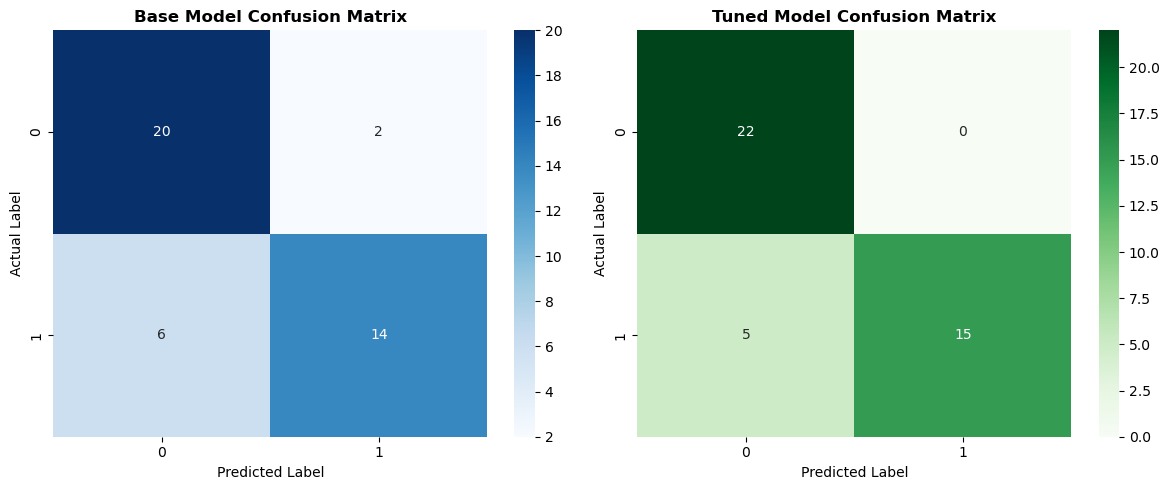

In [7]:
# Assignment 18: Artificial Neural Network
# Case Study: SONAR — Detecting Mines vs. Rocks
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# Ensure reproducibility
np.random.seed(42)
tf.random.set_seed(42)


# 1. Data Exploration and Preprocessing
df = pd.read_csv('sonardataset.csv')
print("Dataset Shape:", df.shape)
print("\nFirst 3 rows:\n", df.head(3))

print("\nMissing Values:", df.isnull().sum().sum())
print("\nClass Distribution (Y):\n", df.iloc[:, -1].value_counts())

# Separate Features (X) and Target (y)
X = df.iloc[:, :-1].values  
y_raw = df.iloc[:, -1].values 

# Encode target labels: 'M' -> 1 (Mine), 'R' -> 0 (Rock)
encoder = LabelEncoder()
y = encoder.fit_transform(y_raw)

# Train-Test Split (80% train, 20% test, stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Data Normalization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nTraining set shape: {X_train_scaled.shape}")
print(f"Testing set shape: {X_test_scaled.shape}")


# 2. Base Model Implementation (ANN)
def build_base_model():
    model = Sequential([
        Input(shape=(60,)),
        Dense(64, activation='relu'),
        Dense(32, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model

base_model = build_base_model()
early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

history_base = base_model.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=16,
    callbacks=[early_stop],
    verbose=0
)

# Base Predictions & Evaluation
y_pred_base = (base_model.predict(X_test_scaled) > 0.5).astype(int).reshape(-1)

base_acc = accuracy_score(y_test, y_pred_base)
base_prec = precision_score(y_test, y_pred_base)
base_rec = recall_score(y_test, y_pred_base)
base_f1 = f1_score(y_test, y_pred_base)

print("\n--- Base Model Performance ---")
print(f"Accuracy:  {base_acc:.4f}")
print(f"Precision: {base_prec:.4f}")
print(f"Recall:    {base_rec:.4f}")
print(f"F1-Score:  {base_f1:.4f}")


# 3. Hyperparameter Tuning
def build_tuned_model(learning_rate=0.0008, dropout_rate=0.2):
    model = Sequential([
        Input(shape=(60,)),
        Dense(128, activation='relu'),
        Dropout(dropout_rate),
        Dense(64, activation='relu'),
        Dropout(dropout_rate),
        Dense(32, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=Adam(learning_rate=learning_rate),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model

tuned_model = build_tuned_model()

history_tuned = tuned_model.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=150,
    batch_size=16,
    callbacks=[EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)],
    verbose=0
)

# Tuned Predictions & Evaluation
y_pred_tuned = (tuned_model.predict(X_test_scaled) > 0.5).astype(int).reshape(-1)

tuned_acc = accuracy_score(y_test, y_pred_tuned)
tuned_prec = precision_score(y_test, y_pred_tuned)
tuned_rec = recall_score(y_test, y_pred_tuned)
tuned_f1 = f1_score(y_test, y_pred_tuned)

print("\n--- Tuned Model Performance ---")
print(f"Accuracy:  {tuned_acc:.4f}")
print(f"Precision: {tuned_prec:.4f}")
print(f"Recall:    {tuned_rec:.4f}")
print(f"F1-Score:  {tuned_f1:.4f}")


# 4. Evaluation, Comparison Table & Visuals
comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Base Model': [base_acc, base_prec, base_rec, base_f1],
    'Tuned Model (Dropout/Layers)': [tuned_acc, tuned_prec, tuned_rec, tuned_f1]
})

print("\n=== Model Comparison Table ===")
display(comparison_df)

# Confusion Matrix Visualizations
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(confusion_matrix(y_test, y_pred_base), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Base Model Confusion Matrix', fontweight='bold')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('Actual Label')

sns.heatmap(confusion_matrix(y_test, y_pred_tuned), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('Tuned Model Confusion Matrix', fontweight='bold')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('Actual Label')

plt.tight_layout()
plt.show()